In [6]:
import os

os.environ["OMP_NUM_THREADS"] = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"] = "8"
os.environ["NUMEXPR_NUM_THREADS"] = "8"

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, correlation_lags
from scipy.fft import set_workers
from scipy.stats import linregress
from itertools import combinations



p3 = '/Volumes/T7/Radio Astronomy/Myrdhin/20261113T160500Z/antenna_03.bin'
p5 = '/Volumes/T7/Radio Astronomy/data/obs/20261113T160500Z/antenna_05.bin'
p6 = '/Volumes/T7/Radio Astronomy/Myrdhin/20261113T160500Z/antenna_06.bin'
p7 = '/Volumes/T7/Radio Astronomy/data/obs/20261113T160500Z/antenna_07.bin'
p9 = '/Volumes/T7/Radio Astronomy/data/obs/20261113T160500Z/antenna_09.bin'

# Function for reading only part of file
def readfile(path, t_start, t_end, fs=10e6, bits=8):
    offset= int(t_start * fs * 8)   # bytes
    count = int((t_end-t_start) * fs) 

    return np.fromfile(path, 
                   np.complex64, 
                   count= count,
                   offset = offset)


In [7]:

# Determine sample offset
def correlate_A_B(A, B, fs=10e6):
    with set_workers(8):
        corr = correlate(A, B, mode='full', method='fft')
        lags = correlation_lags(len(A), len(B), mode='full')

    k = np.argmax(np.abs(corr))
    shift = lags[k]                      # samples

    print(f"Sample shift: {shift}")
    return corr, shift

# Shift data to align
def shift_A_B(A, B, shift):
    if shift > 0:
        new_A = A[shift:]
        new_B = B[:-shift]
    elif shift < 0:
        new_A = A[:shift]
        new_B = B[-shift:]
    else:
        new_B, new_B = A.copy(), B.copy()

    return new_A, new_B



In [8]:
# ## Quick testrun for two antennas
# # Read files
# ant5 = readfile(p5, 1, 10)
# ant7 = readfile(p7, 1, 10)

# delay_5_7 = correlate_A_B(ant5, ant7)
# new5, new7 = shift_A_B(ant5, ant7, delay_5_7)

# # Correlation should be 0 after shift, check if this is the case
# c2 = correlate(new5, new7, mode='full', method='fft')
# l2 = correlation_lags(len(new5), len(new7), mode='full')
# print(l2[np.argmax(np.abs(c2))])

In [9]:
# Function for correlating antennas (from notebook 2nd session)
def fx_correlating_interferometer(cv_1, cv_2, num_chan:int):
    # "cv" stands for "complex voltage"
    num_samples = min(len(cv_1), len(cv_2))
    result = np.zeros(num_chan, dtype=np.complex64)
    spectra_added = 0
    for i in range(0, num_samples, num_chan):
        if i + num_chan > num_samples: # can't make a full spectrum anymore
            break
        spectrum_1 = np.fft.fft(cv_1[i:i+num_chan], norm='ortho')
        spectrum_2 = np.fft.fft(cv_2[i:i+num_chan], norm='ortho')
        result        += spectrum_1*np.conj(spectrum_2)
        spectra_added += 1
    if spectra_added > 0:
        return np.fft.fftshift(result/spectra_added)
    else:
        raise ValueError("ERROR: Cannot form %a channels from sampled data of lengths %r and %r",
                         num_chan, len(cv_1), len(cv_2))

# Finding sub-sample delay by fitting the slope of the phase of the FFT
def fit_spectrum(spectrum, fit_interval=None, fs=10e6, num_chan=1024):
    channels = np.arange(len(spectrum))
    angles = np.unwrap(np.angle(spectrum))

    # compute mean and std
    mean = np.mean(angles)
    std = np.std(angles)

    # mask away the edges
    mask = np.zeros(len(spectrum), dtype=bool)

    if fit_interval == None:
        mask[num_chan//2 - 100:num_chan//2 + 100] = True
    else:
        mask[fit_interval[0]:fit_interval[1]] = True

    # mask away the peaks
    mask[np.abs(angles-mean) > 2 * std] = False

    channels_mask = channels[mask]
    angles_mask = angles[mask]

    # fit linear regression to masked phase array
    popt = linregress(channels_mask, angles_mask)
    slope, b = popt[0], popt[1]

    # plotting code
    plt.plot(channels_mask, angles_mask)
    plt.plot(channels_mask, channels_mask * slope + b)
    plt.ylim(mean-0.01*np.abs(mean), mean+0.01*np.abs(mean))
    plt.show()

    # convert slope to time delay (in ns)
    ns_per_rad = N / (2*np.pi*fs) * 1e9
    tau_ns     = slope * ns_per_rad

    # compute the error based on the fit accuracy
    tau_err_ns = popt.stderr * ns_per_rad

    print(f'fractional delay = {tau_ns:.2f} +/- {tau_err_ns:.2f} ns')

    return tau_ns, tau_err_ns

# # test the subsample time delay computation
# N = 1024 # number of channels
# spectrum = fx_correlating_interferometer(new5, new7, num_chan=N)
# plt.plot(spectrum)
# plt.show()
# tau_ns, tau_err_ns = fit_spectrum(spectrum)

In [18]:
# Function for finding clock drift, optionally with subsample accuracy


def check_clock_drift(path_A, path_B, t_interval, scarce=1, subsample=True, fs=10e6):
    s_measure = os.path.getsize(path_A)
    t_measure = int(s_measure/8/fs)   # s
    # print('Measuring time: ', t_measure)

    time_intervals = np.arange(0, t_measure-t_interval, t_interval)
    delays = np.zeros(len(time_intervals))
    errs = delays.copy()


    for i, t_start in enumerate(time_intervals):
        if i % scarce != 0:
            continue

        t_end = t_start + t_interval
        # print('Currently at t = ', str(t_start), '-', str(t_end), ' s')

        dataA = readfile(path_A, t_start, t_end)
        dataB = readfile(path_B, t_start, t_end)

        corr, delay = correlate_A_B(dataA, dataB)
        del corr

        if subsample:
            newA, newB = shift_A_B(dataA, dataB, delay)
            spectrum = fx_correlating_interferometer(newA, newB, num_chan=1024)
            subsample_delay, subsample_delay_err = fit_spectrum(spectrum) 

            delays[i] = 1e9 * delay / fs + subsample_delay   # in ns
            errs[i] = subsample_delay_err
        else:
            delays[i] = 1e9 * delay / fs   # in ns

        
        del dataA
        del dataB

    return delays, errs, time_intervals



## **Code for quick check**

### Antenna cross-correlation

In [19]:
# Antenna paths
antennas = [1, 2, 3, 4, 5, 6, 7, 8, 9]
paths = [p3, p5, p9, p6, p7, p9, p9, p7, p6]   # placeholder nonsense
n_ants = len(antennas)

# Check length of data
for i, p in enumerate(paths):
    try: print('Size of file: ', os.path.getsize(p))
    except: print('No valid path for antenna', str(antennas[i]))

Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000
Size of file:  19200000000


antenna 1 vs 2: Sample shift: 73370
antenna 1 vs 3: Sample shift: 11918
antenna 1 vs 4: Sample shift: 135689
antenna 1 vs 5: Sample shift: -547
antenna 1 vs 6: Sample shift: 11918
antenna 1 vs 7: Sample shift: 11918
antenna 1 vs 8: Sample shift: -547
antenna 1 vs 9: Sample shift: 135689
antenna 2 vs 3: Sample shift: 3754
antenna 2 vs 4: Sample shift: 4105
antenna 2 vs 5: Sample shift: -8710
antenna 2 vs 6: Sample shift: 3754
antenna 2 vs 7: Sample shift: 3754
antenna 2 vs 8: Sample shift: -8710
antenna 2 vs 9: Sample shift: 4105
antenna 3 vs 4: Sample shift: 11658
antenna 3 vs 5: Sample shift: -12464
antenna 3 vs 6: Sample shift: 0
antenna 3 vs 7: Sample shift: 0
antenna 3 vs 8: Sample shift: -12464
antenna 3 vs 9: Sample shift: 11658
antenna 4 vs 5: Sample shift: 1251
antenna 4 vs 6: Sample shift: -11658
antenna 4 vs 7: Sample shift: -11658
antenna 4 vs 8: Sample shift: 1251
antenna 4 vs 9: Sample shift: 0
antenna 5 vs 6: Sample shift: 12464
antenna 5 vs 7: Sample shift: 12464
antenna

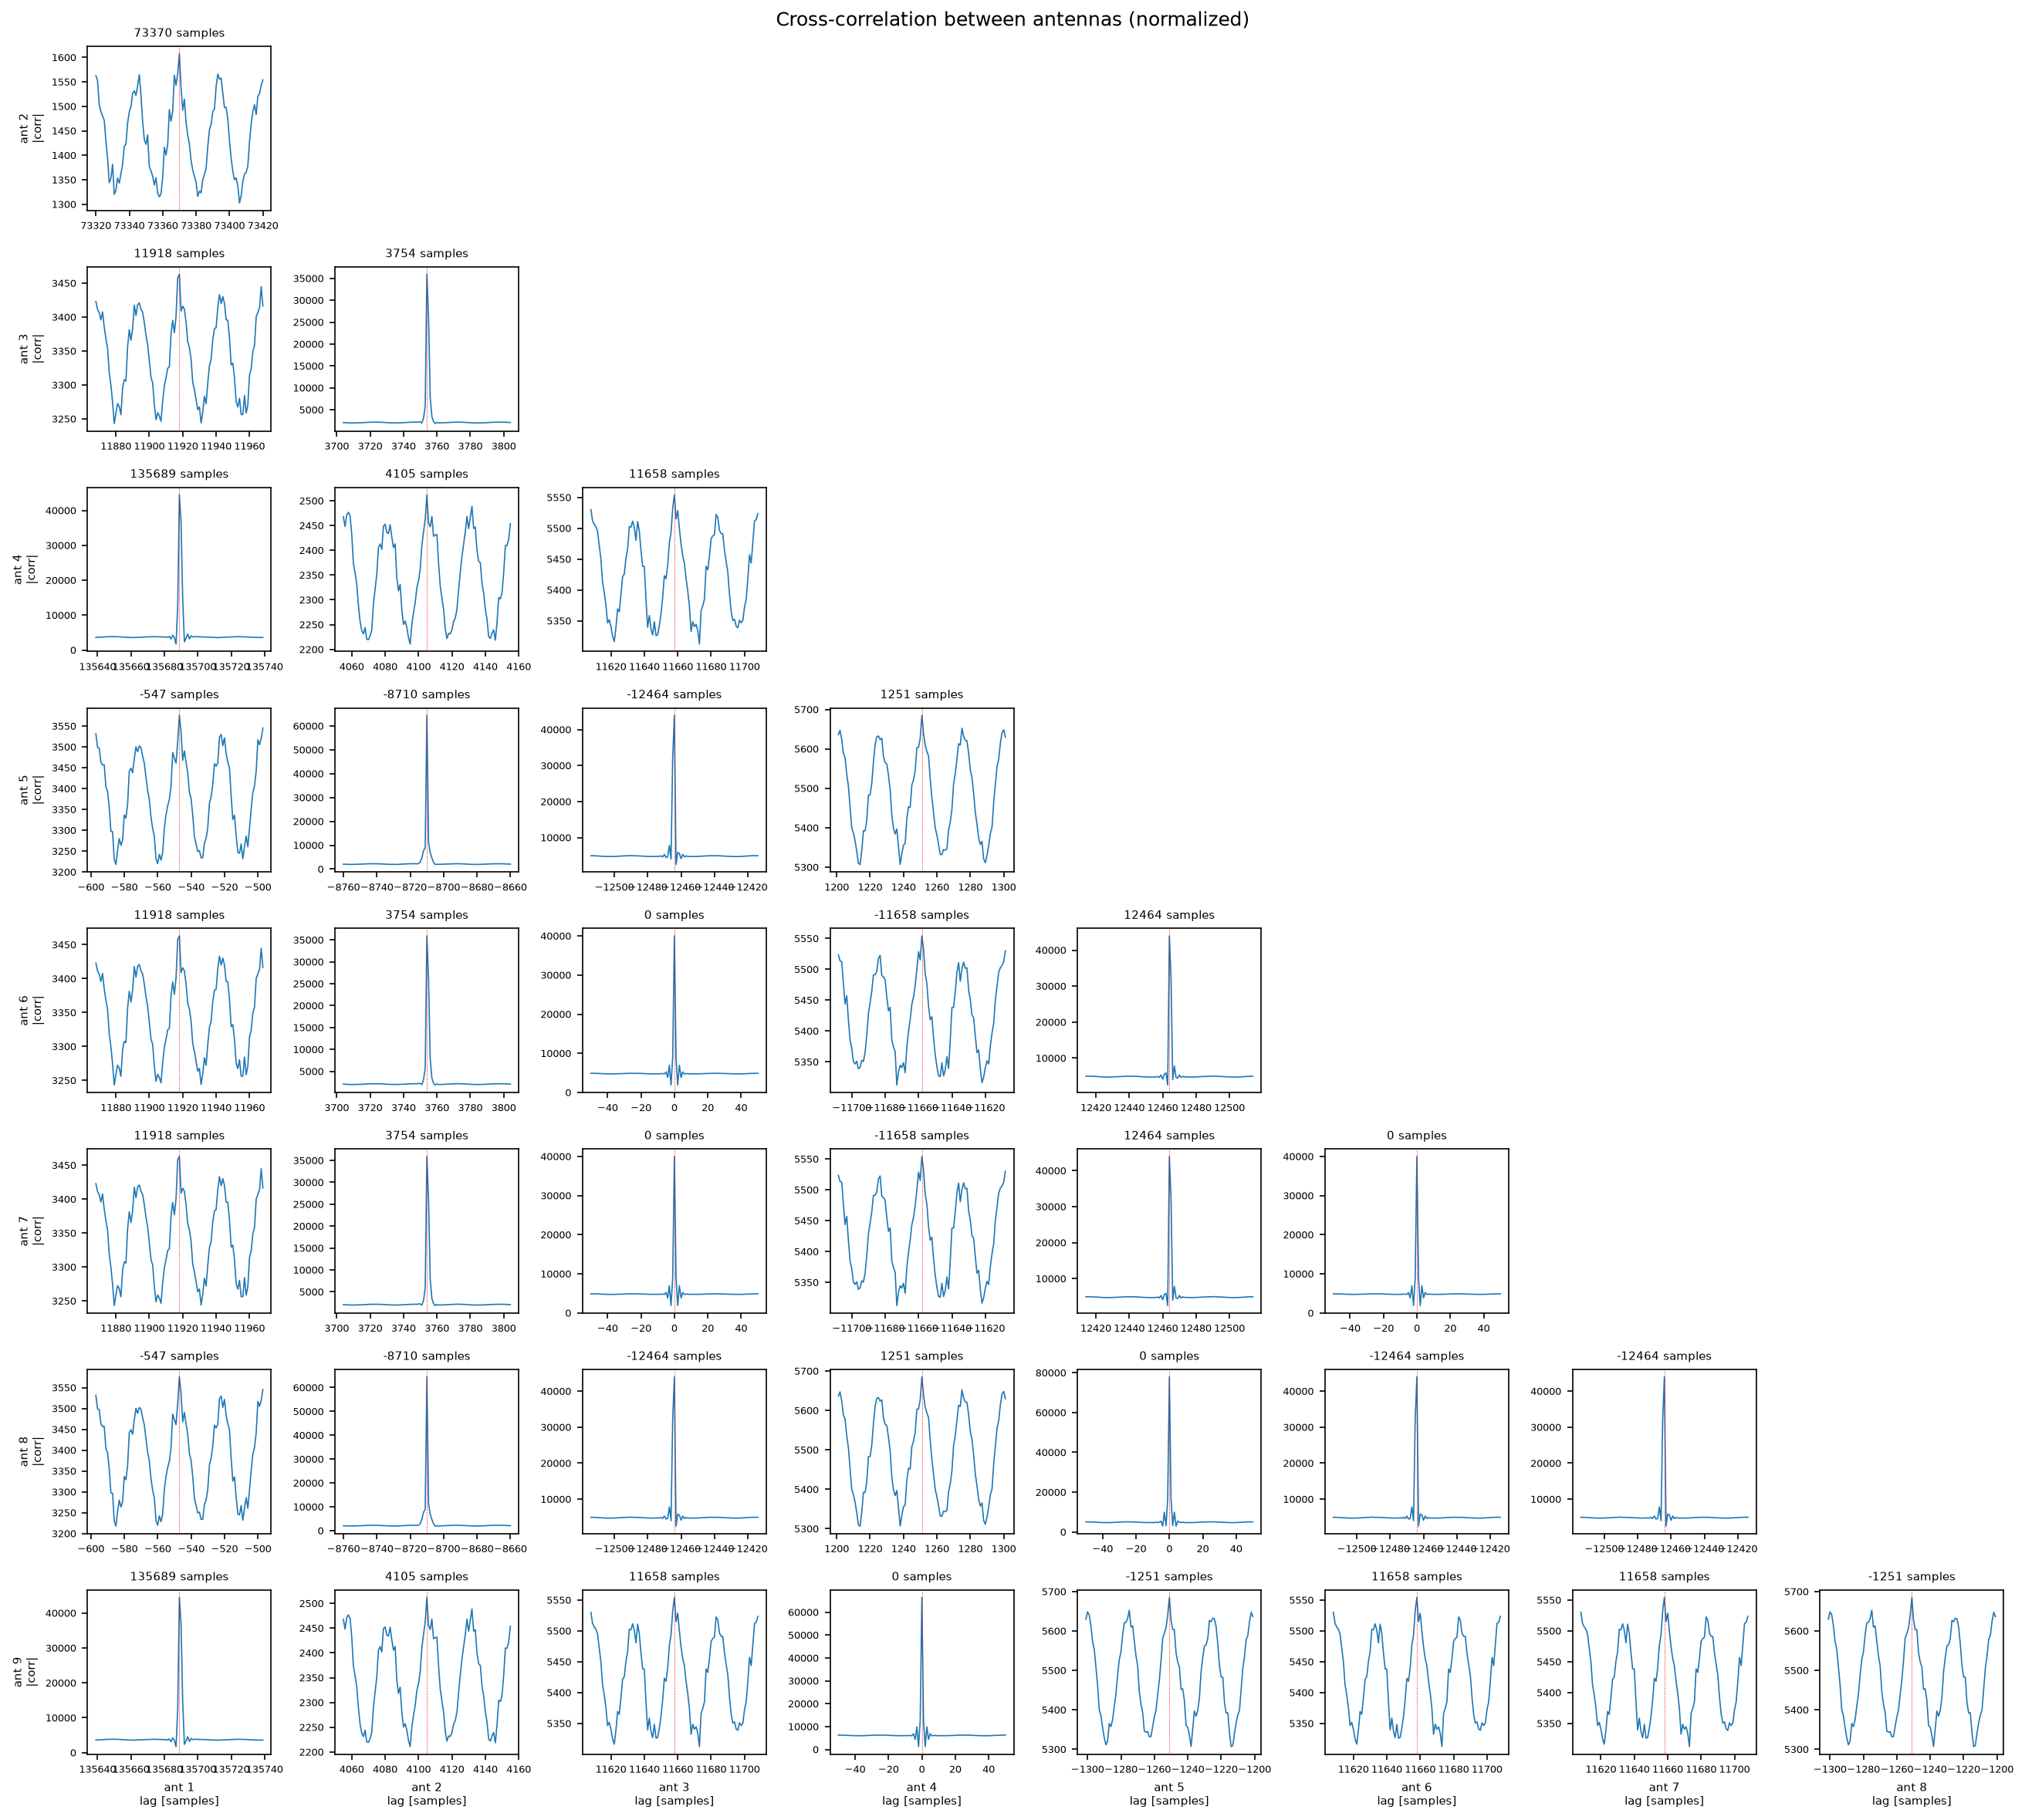

In [20]:
# View a (coarse) cross correlation

t_coarse = (1, 2)   # s

half = 50   # samples shown on each side of the peak
lags = {}   # integer delay per pair (used later by shift_A_B)
cuts = {}   # |corr| around the peak per pair

for a in range(n_ants):
    read_a = readfile(paths[a], t_coarse[0], t_coarse[1])
    for b in range(a+1, n_ants):
        read_b = readfile(paths[b], t_coarse[0], t_coarse[1])
        print(f'antenna {antennas[a]} vs {antennas[b]}: ', end='')
        corr, shift = correlate_A_B(read_a, read_b)
        lags[(a, b)] = shift
        k = shift + len(read_b) - 1          # index of the peak in the 'full' correlation
        cuts[(a, b)] = np.abs(corr[k-half:k+half+1])
        del corr
        del read_b

    del read_a

#  corner plot of the correlation between each antenna pair
lag_axis = np.arange(-half, half + 1)

fig, axes = plt.subplots(n_ants-1, n_ants-1, figsize=(2.2*(n_ants-1), 2.0*(n_ants-1)), squeeze=False, dpi=150)
for r in range(n_ants-1):
    for c in range(n_ants-1):
        ax = axes[r, c]
        if c > r:
            ax.axis('off')
            continue
        pair = (c, r+1)
        ax.plot(lag_axis + lags[pair], cuts[pair], lw=0.8)
        ax.axvline(lags[pair], color='r', lw=0.5, ls=':')
        ax.set_title(f'{lags[pair]} samples', fontsize=7)
        ax.tick_params(labelsize=6)
        if r == n_ants-2:
            ax.set_xlabel(f'ant {antennas[c]}\nlag [samples]', fontsize=7)
        if c == 0:
            ax.set_ylabel(f'ant {antennas[r+1]}\n|corr|', fontsize=7)
fig.suptitle('Cross-correlation between antennas (normalized)')
fig.tight_layout()
plt.savefig('cross_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

### Antenna quick clock drift


Reference: 2, comparing: 1
Sample shift: -19820
Sample shift: -68004
Sample shift: 4669
Sample shift: -52573
Sample shift: -28490
Sample shift: 13723

Reference: 2, comparing: 3
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754

Reference: 2, comparing: 4
Sample shift: 18606
Sample shift: 12563
Sample shift: -20720
Sample shift: 1886
Sample shift: -5896
Sample shift: 9570

Reference: 2, comparing: 5
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710

Reference: 2, comparing: 6
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754

Reference: 2, comparing: 7
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754
Sample shift: 3754

Reference: 2, comparing: 8
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710
Sample shift: -8710


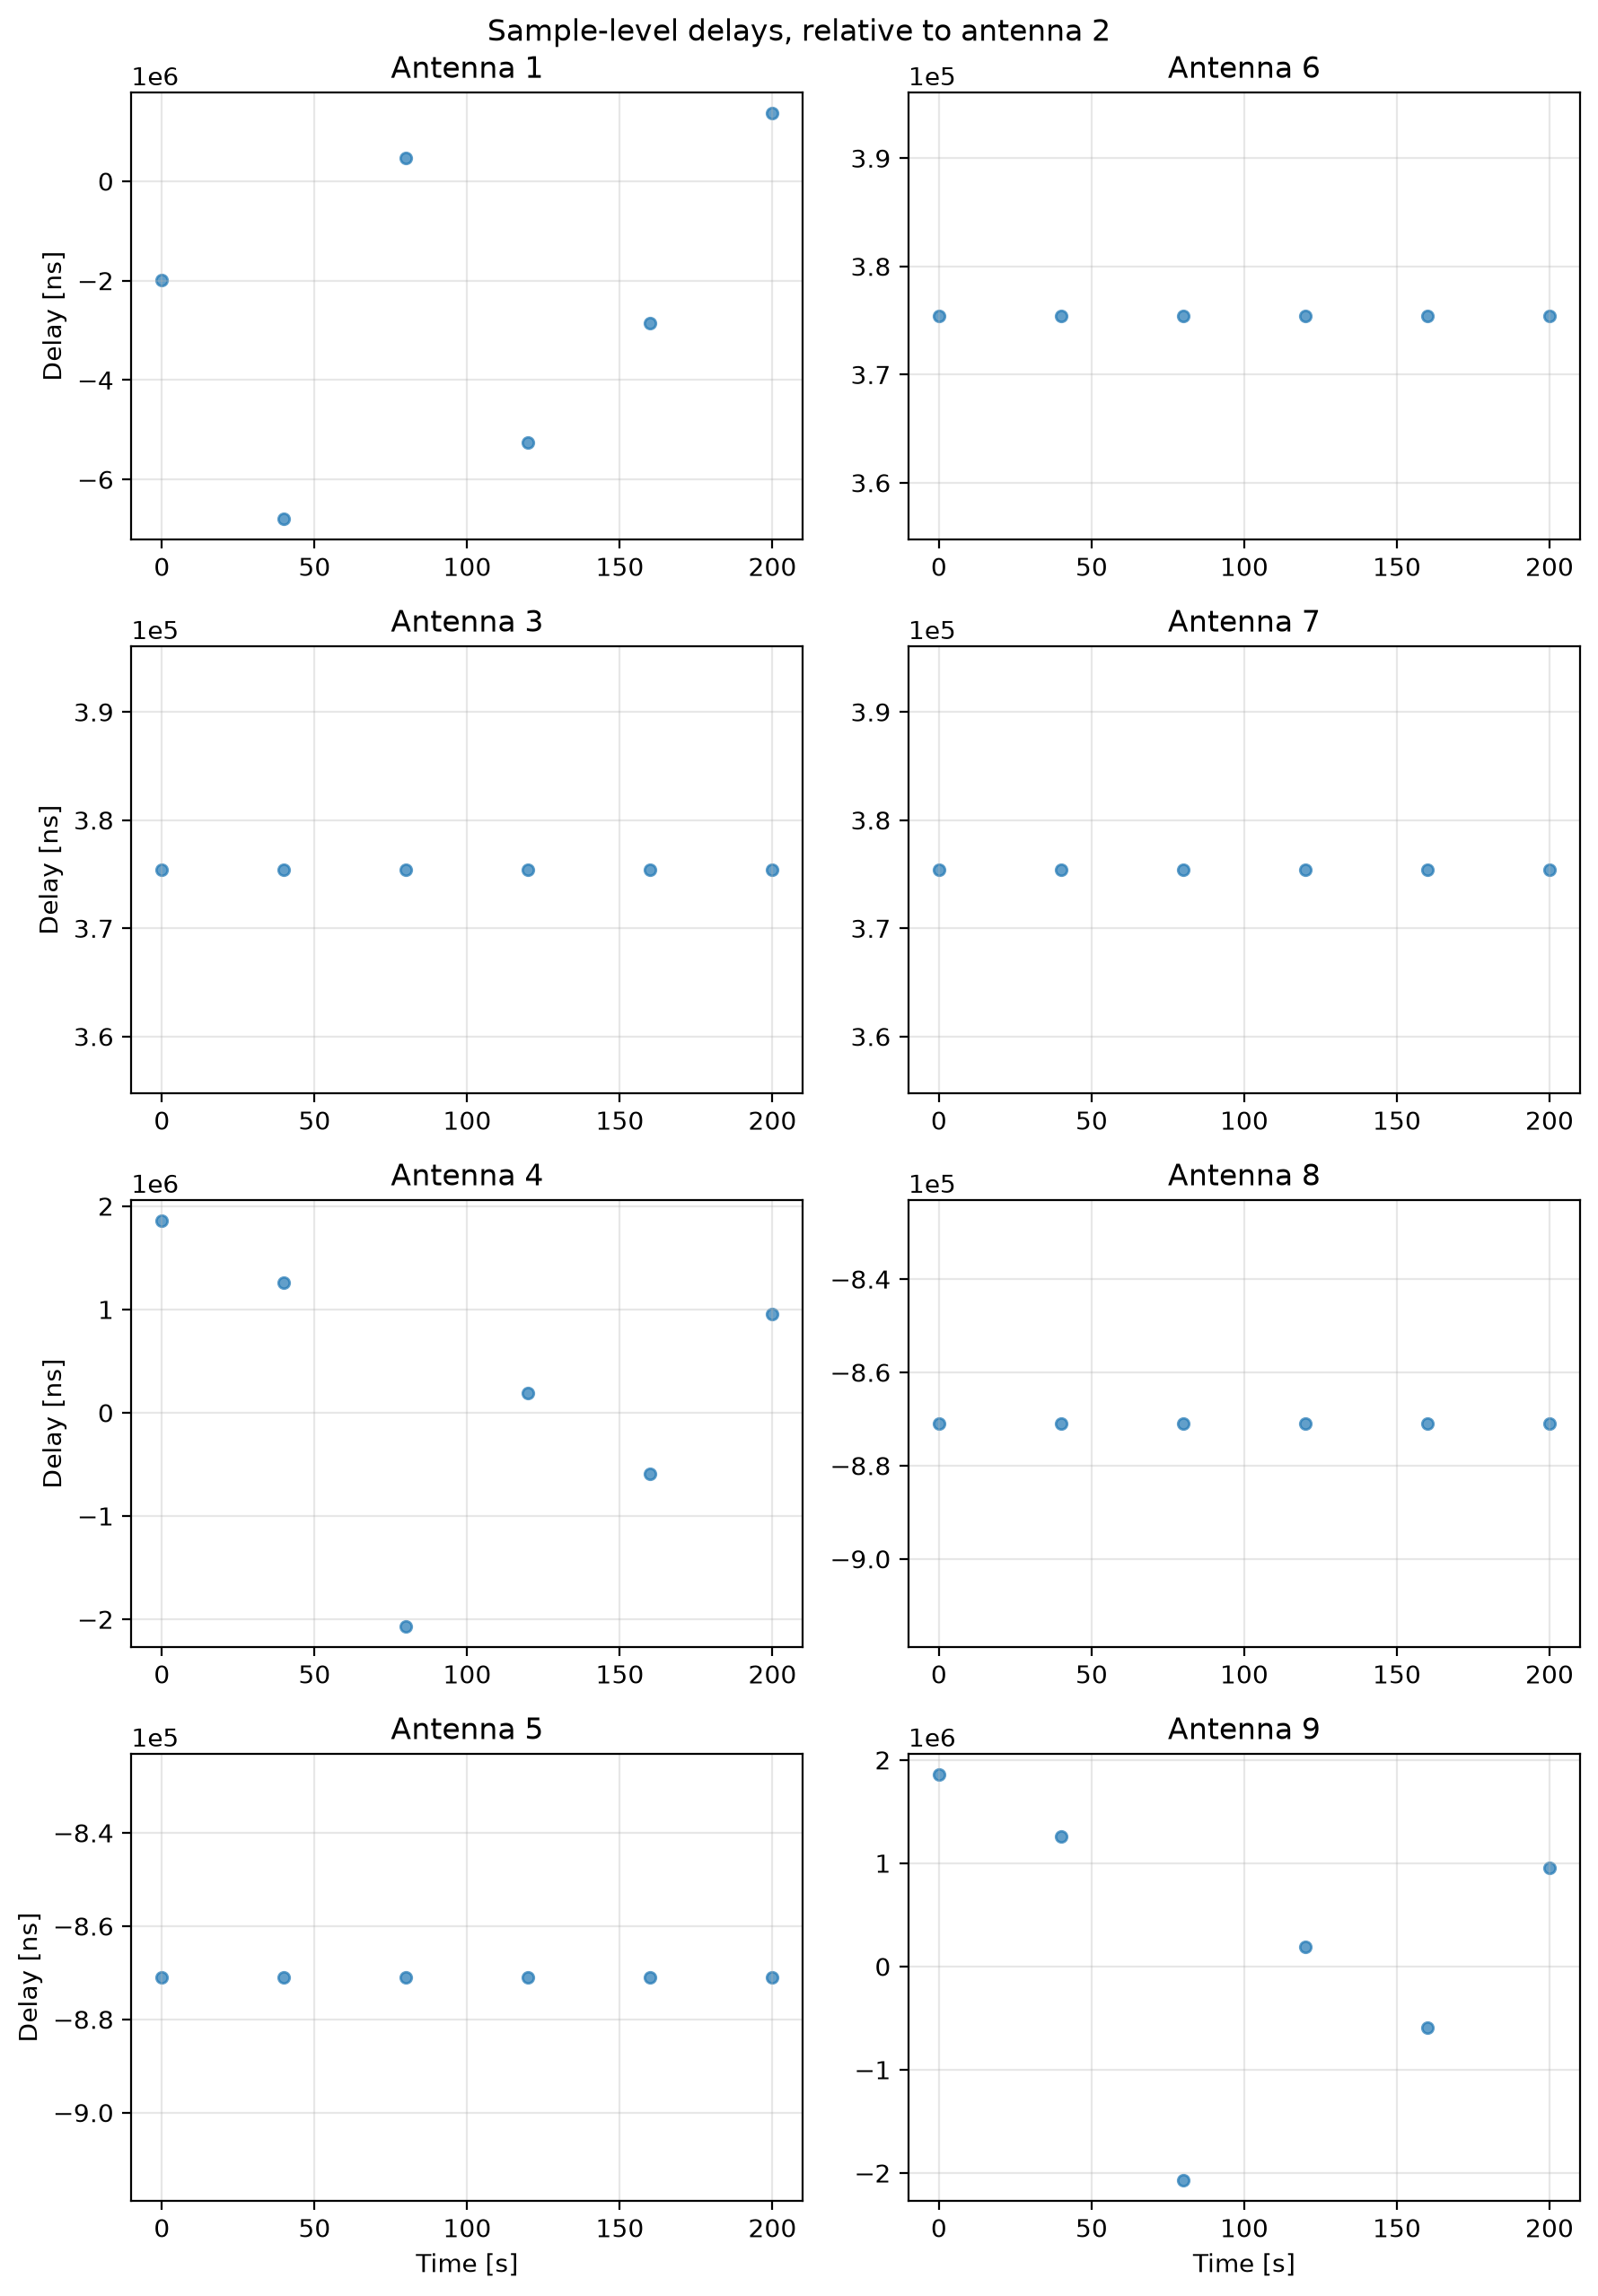

In [21]:
fig, ax = plt.subplots(4, 2, figsize=(9, 13), dpi=200, tight_layout=True, squeeze=False)

reference_idx = 1
jump = int(40)

p_a = paths[reference_idx]
count = 0

for i, p_b in enumerate(paths):
    if p_a == p_b:
        continue

    print(f"\nReference: {antennas[reference_idx]}, comparing: {antennas[i]}")

    delays, errs, time_intervals = check_clock_drift(p_a, p_b, 1, scarce=jump, subsample=False, fs=10e6)

    row = count % 4
    col = count // 4

    ax[row, col].scatter(time_intervals[::jump], delays[::jump], s=20, alpha=0.7)
    ax[row, col].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    ax[row, col].set_title(f'Antenna {antennas[i]}')
    if row == 3:
        ax[row, col].set_xlabel('Time [s]')
    if col == 0:
        ax[row, col].set_ylabel('Delay [ns]')
    ax[row, col].grid(alpha=0.3)

    count += 1

for j in range(count, 8):
    ax[j % 4, j // 4].set_visible(False)

fig.suptitle(f'Sample-level delays, relative to antenna {antennas[1]}')
fig.tight_layout()
plt.savefig('clock_drift_test.pdf', bbox_inches='tight')
plt.show()